In [49]:
import numpy as np
import matplotlib.pyplot as plt

In [50]:
HEIGHT = 200
WIDTH = 300
I = 0.1
dh = 0.1
beta = 0.5

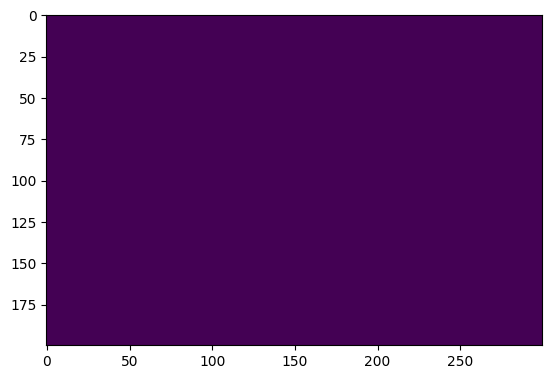

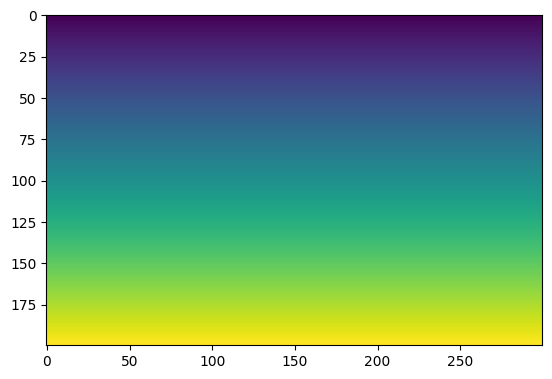

In [51]:
# Generate the space
M = np.zeros((HEIGHT, WIDTH), float)
plt.imshow(M)
plt.show()

# Apply the gradient function
for row in range(HEIGHT):
    M[row][:] = row*I
plt.imshow(M)
plt.show()

Raindrop path length: 30 unique tiles.


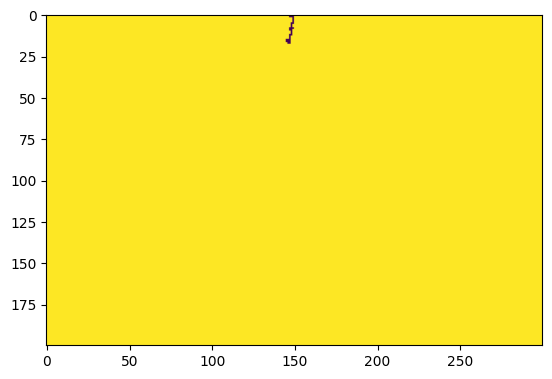

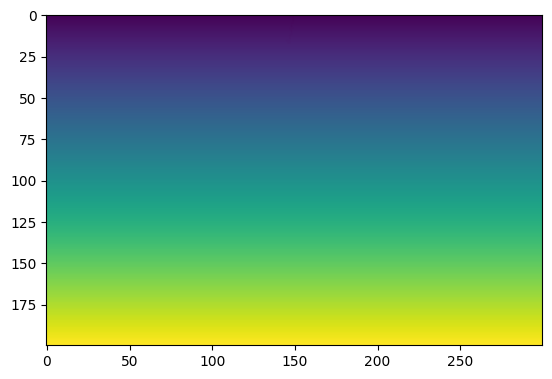

In [52]:
# Pick a random spot on the map
def random_coordinate():
    # np.random.randint is exclusive of the high value, 
    # so use HEIGHT and WIDTH to include the edge rows/columns
    h = np.random.randint(0, HEIGHT)
    w = np.random.randint(0, WIDTH)
    return (h, w)

def w_function(x):
    if x < 0:
        return 0
    else:
        return np.exp(beta * x)

def water_flow(position, M, perfect=False):
    h, w = position
    # apply boundary conditions
    if h == HEIGHT-1:
        # can't go up out of the board
        up = np.inf
    else:
        up = M[h+1, w]

    down = M[h-1, w] if h > 0 else np.inf

    # PBC for horizontal motion
    left = M[h, (w-1) % M.shape[1]]
    right = M[h, (w+1) % M.shape[1]]

    # select the next position
    initial = M[position]
    move_up = w_function(initial - up)
    move_down = w_function(initial - down)
    move_left = w_function(initial - left)
    move_right = w_function(initial - right)

    omega = move_down + move_left + move_right + move_up

    if omega == 0 or not np.isfinite(omega):
        prob = np.ones(4) / 4
    else:
        prob = np.array([move_down, move_left, move_right, move_up]) / omega

    move_matrix = [[-1,0],[0,-1],[0,1],[1,0]]

    if perfect:
        return position + move_matrix[np.argmax(prob)]

    direction = np.random.choice(4, p=prob)
    return (h + move_matrix[direction][0], (w + move_matrix[direction][1]) % M.shape[1])

def rain(M, verbose=False):
    pos = random_coordinate()
    
    # Use a set to log unique coordinates visited by this raindrop
    visited = set()
    visited.add(pos)

    for i in range(2000):
        if pos[0] == 0:
            # The rain has reached the sea
            break

        # Iteratively move the water
        pos = water_flow(pos, M)
        visited.add(pos) # Sets automatically handle duplicates

    # Apply the erosion to the matrix (each cell ONLY ONCE)
    erosion_matrix = np.zeros(M.shape)
    for cell in visited:
        erosion_matrix[cell] = -dh

    if verbose:
        print(f"Raindrop path length: {len(visited)} unique tiles.")
        plt.imshow(erosion_matrix)
        plt.show()
        
    M += erosion_matrix

rain(M,verbose=True)
plt.imshow(M)

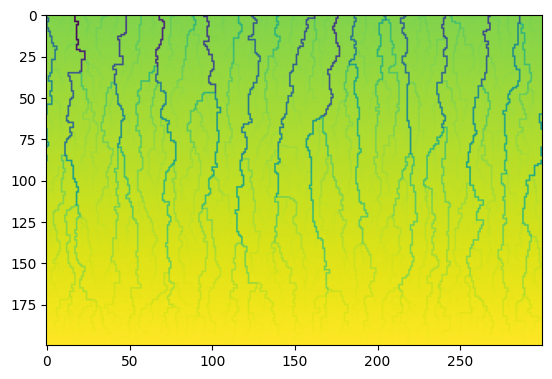

In [53]:
raindrops = 10000
for i in range(raindrops):
    rain(M)
    # if i % 100:
    #     rain(M, True)
    #     plt.imshow(M)
    #     plt.show()

plt.imshow(M)

--- River Collections ---
River ID:   0 -> Area: 2756 pixels
River ID:   1 -> Area:    1 pixels
River ID:   2 -> Area:    3 pixels
River ID:   3 -> Area:    1 pixels
River ID:   4 -> Area:    1 pixels
River ID:   5 -> Area:   28 pixels
River ID:   6 -> Area:    1 pixels
River ID:   7 -> Area:    5 pixels
River ID:   8 -> Area:    1 pixels
River ID:   9 -> Area:    1 pixels
River ID:  10 -> Area:   78 pixels
River ID:  11 -> Area:    1 pixels
River ID:  12 -> Area:    2 pixels
River ID:  13 -> Area:    2 pixels
River ID:  14 -> Area:    1 pixels
River ID:  15 -> Area:   69 pixels
River ID:  16 -> Area:    1 pixels
River ID:  17 -> Area: 1516 pixels
River ID:  18 -> Area:    1 pixels
River ID:  19 -> Area:    3 pixels
River ID:  20 -> Area:    4 pixels
River ID:  21 -> Area:    5 pixels
River ID:  22 -> Area:    1 pixels
River ID:  23 -> Area:  102 pixels
River ID:  24 -> Area:    1 pixels
River ID:  25 -> Area:    2 pixels
River ID:  26 -> Area:    1 pixels
River ID:  27 -> Area:   16 p

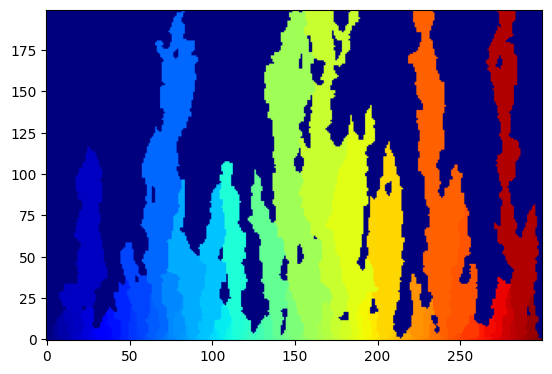

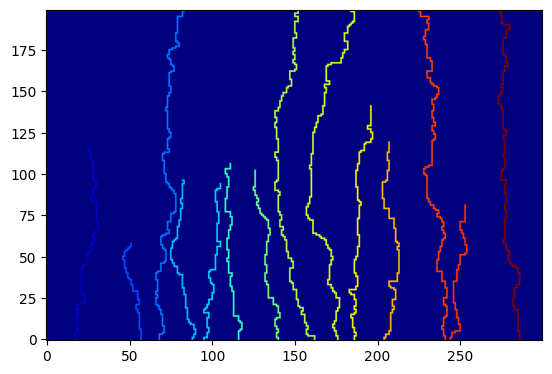

In [57]:
def get_next_perfect_step(pos):
    h, w = pos
    up = np.inf if h == HEIGHT - 1 else M[h + 1, w]
    down = M[h - 1, w] if h > 0 else np.inf
    left = M[h, (w - 1) % WIDTH]
    right = M[h, (w + 1) % WIDTH]

    initial = M[pos]
    move_up = w_function(initial - up)
    move_down = w_function(initial - down)
    move_left = w_function(initial - left)
    move_right = w_function(initial - right)

    omega = move_down + move_left + move_right + move_up
    if omega == 0 or not np.isfinite(omega):
        prob = np.ones(4) / 4
    else:
        prob = np.array([move_down, move_left, move_right, move_up]) / omega

    move_matrix = [[-1, 0], [0, -1], [0, 1], [1, 0]]

    # Default down if flat land/pit tie, otherwise take argmax
    direction = 0 if np.all(prob == prob[0]) else np.argmax(prob)
    
    return (h + move_matrix[direction][0], (w + move_matrix[direction][1]) % WIDTH)

def trace_and_plot_paths(M):
    HEIGHT, WIDTH = M.shape
    collection_matrix = np.full((HEIGHT, WIDTH), -1, dtype=int)
    river_matrix = np.full((HEIGHT, WIDTH), -1, dtype=int)
    longest_paths = {}

    # Grid Traversal 
    for h in range(HEIGHT):
        for w in range(WIDTH):
            start_pos = (h, w)

            # Base case: Starting point is already sea level
            if h == 0:
                river_id = w
                collection_matrix[start_pos] = river_id
                if river_id not in longest_paths:
                    longest_paths[river_id] = [start_pos]
                continue

            current_path = [start_pos]
            visited_set = {start_pos}
            pos = start_pos
            trapped = False

            # Trace until row 0
            while pos[0] > 0:
                next_pos = get_next_perfect_step(pos)

                # Cycle-break guard for depression pits
                if next_pos in visited_set:
                    trapped = True
                    break

                current_path.append(next_pos)
                visited_set.add(next_pos)
                pos = next_pos


            if not trapped:
                river_id = current_path[-1][1]  # The column position at row 0
                
                # Mark entire path in collection matrix
                for node in current_path:
                    collection_matrix[node] = river_id

                # Track the longest path configuration for this river ID
                if river_id not in longest_paths or len(current_path) > len(longest_paths[river_id]):
                    longest_paths[river_id] = current_path

    # 4. Statistical Filtering
    unique_ids, counts = np.unique(collection_matrix, return_counts=True)
    area_dict = dict(zip(unique_ids, counts))

    print("--- River Collections ---")
    for rid in sorted(area_dict.keys()):
        if rid != -1:  # Disregard unassigned background pixels
            print(f"River ID: {rid:3d} -> Area: {area_dict[rid]:4d} pixels")

    # Filter out minor streams (Area must be strictly > 500)
    major_rivers = {rid for rid, area in area_dict.items() if rid != -1 and area > 500}

    # Burn major channels into the river matrix
    for rid in major_rivers:
        if rid in longest_paths:
            for node in longest_paths[rid]:
                river_matrix[node] = rid


    plt.imshow(collection_matrix, cmap='jet', origin='lower')
    plt.show()

    # Main rivers
    plt.imshow(river_matrix, cmap='jet', origin='lower')

    plt.show()

    # return collection_matrix, river_matrix
    return

trace_and_plot_paths(M)